# Detect money mule activity in synthetic accounts

Which accounts should an investigator review for current money mule activity? Train a local Kumo Engine model on linked accounts and transfers, compare it with logistic regression, and score newly added accounts.

**Kumo Engine · Local Linux CPU notebook · Synthetic data**

Use a prepared [Linux environment](https://docs.nvidia.com/sdgm/kumo-engine/get-started-with-kumo-engine/installation/linux-machine-deployment) and writable local scratch.
This example adapts the account network in the [money-laundering workflow](https://docs.nvidia.com/sdgm/kumo-engine/get-started-with-kumo-engine/workflows-and-solutions/fraud/money-laundering-detection) to classify simulated current mule activity. It does not predict future suspicious-activity reports.


## Recognize the account behavior

Money mules receive and move illicit funds on someone else's behalf. The [FBI's unwitting, witting, and complicit categories](https://www.fbi.gov/how-we-can-help-you/common-frauds-and-scams/money-mules) describe awareness; this example predicts account activity, not a person's intent.

The simulation includes rapid forwarding, funnel accounts, and intermediary chains. Legitimate household transfers, merchant collections, and payroll distributions create similar shapes. A score prioritizes review; it does not establish wrongdoing. Synthetic ground truth identifies participating intermediaries, rather than labeling every connected victim or recipient as a mule.


## Install

Install Engine and the libraries used for data preparation, the comparison baseline, and the precision–recall plot into your prepared notebook kernel.


In [ ]:
%pip install -q kumo-engine pandas numpy pyarrow scikit-learn matplotlib


## Import the workflow tools

Use the local Engine APIs for graph construction, supplied training rows, prediction, and model retention.


In [1]:
import json
import os
import shutil
from datetime import timedelta
from pathlib import Path
from tempfile import mkdtemp

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import kumo.engine as kumo
from kumo.engine.trainer.output_config import ModelOutputConfig, TrainingTableOutputConfig
from kumoapi.graph import Edge
from kumoapi.model_plan import RunMode
from kumoapi.train import TrainingTableSpec
from kumoapi.typing import Dtype, Stype


/tmp/kumo-notebook-runtime/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Set the example parameters

Scratch defaults to `kumo_scratch` under the current directory; set `KUMO_SCRATCH` to use another writable local directory. Keep `SMOKE_MODE=False` for FAST training; the optional one-epoch mode only checks the pipeline.
The 10% simulated mule prevalence and 5% review budget are teaching choices, not estimates or operational policy. Account counts are multiples of 20 so half the ten-account scenarios can represent legitimate activity.


In [2]:
SCRATCH_PARENT = Path(os.environ.get("KUMO_SCRATCH", str(Path.cwd() / "kumo_scratch"))).expanduser().resolve()
OUTPUT_PARENT = Path.cwd() / "kumo_example_runs"
SEED = 42
N_ACCOUNTS = 2000
N_BACKGROUND_TRANSFERS = 20000
N_NEW_ACCOUNTS = 100
HISTORY_DAYS = 90
CUTOFF = pd.Timestamp("2026-10-01")  # Timezone-naive UTC throughout.
REVIEW_FRACTION = 0.05
SMOKE_MODE = False
REMOVE_RUN_SCRATCH = False

SCRATCH_PARENT.mkdir(parents=True, exist_ok=True)
if not SCRATCH_PARENT.is_dir():
    raise ValueError("KUMO_SCRATCH must point to a writable local directory.")
if N_ACCOUNTS < 200 or N_NEW_ACCOUNTS < 20 or any(
    n % 20 for n in (N_ACCOUNTS, N_NEW_ACCOUNTS)
):
    raise ValueError("Use multiples of 20: at least 200 historical and 20 new accounts.")
if HISTORY_DAYS < 30 or N_BACKGROUND_TRANSFERS < 1 or not 0 < REVIEW_FRACTION <= 1:
    raise ValueError("Use at least 30 history days, positive background traffic, and a review fraction in (0, 1].")

OUTPUT_PARENT.mkdir(parents=True, exist_ok=True)
run_dir = Path(mkdtemp(prefix="synthetic_money_muling-", dir=OUTPUT_PARENT))
scratch_dir = Path(mkdtemp(prefix="synthetic_money_muling-", dir=SCRATCH_PARENT))
source_dir, output_dir = run_dir / "source", run_dir / "output"
source_dir.mkdir()
output_dir.mkdir()
kumo.configure(scratch_dir=scratch_dir)
destination = kumo.FileConnector(root_dir=str(output_dir))
print("Retained files:", run_dir)
print("Scratch:", scratch_dir)


Retained files: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_example_runs/synthetic_money_muling-zkqzt0ut
Scratch: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_scratch/synthetic_money_muling-9u3v45ec


## Generate synthetic example data

Run the next two cells to create historical accounts and transfers, plus a separate batch reserved for scoring. You can skim the generation code; the Kumo workflow starts at **Build the graph**.

| Table | Contents |
| --- | --- |
| `accounts` | Invented IDs, opening dates, account types, and a constant target placeholder |
| `transactions` | Transfer IDs, times, amounts in one currency, and channels |
| `inputs`, `outputs` | Sender and receiver postings connecting accounts to transfers |
| Separate simulation truth | Mule outcomes and scenario membership, never graph features |

Each planted scenario contains ten accounts, with two intermediaries. Half the scenarios involve simulated illicit funds; half are legitimate lookalikes. Timing, amounts, channels, and retention overlap between classes. Random background transfers can connect scenarios. Account IDs and attributes do not encode the hidden roles.


In [3]:
def make_network(n_accounts, n_background, prefix, seed):
    rng = np.random.default_rng(seed)
    ids = np.array([f"synthetic-{prefix}-account-{i:05d}" for i in range(n_accounts)])
    members = rng.permutation(n_accounts).reshape(-1, 10)
    illicit = np.zeros(len(members), dtype=bool)
    illicit[rng.choice(len(members), len(members) // 2, replace=False)] = True
    accounts = pd.DataFrame({
        "account_id": ids,
        "opened_at": CUTOFF - pd.to_timedelta(rng.integers(HISTORY_DAYS + 30, 3000, n_accounts), unit="D"),
        "account_type": rng.choice(["personal", "business"], n_accounts, p=[0.8, 0.2]),
        # Only a schema placeholder. Actual outcomes live in supplied training rows.
        "mule_label": np.zeros(n_accounts, dtype=np.int64),
    })
    truth = pd.DataFrame({"account_id": ids, "is_mule": False,
                          "network_id": "", "scenario": "", "role": "ordinary"})
    records = []

    def transfer(sender, receiver, when, amount, network="background", episode="background"):
        records.append((ids[sender], ids[receiver], when, max(0.01, round(float(amount), 2)), network, episode))

    senders = rng.integers(0, n_accounts, n_background)
    receivers = (senders + rng.integers(1, n_accounts, n_background)) % n_accounts
    times = CUTOFF - pd.to_timedelta(rng.integers(1, HISTORY_DAYS * 86400, n_background), unit="s")
    for sender, receiver, when, amount in zip(
        senders, receivers, times, rng.lognormal(4.5, 1.2, n_background), strict=True
    ):
        transfer(sender, receiver, when, amount)

    for group, account_positions in enumerate(members):
        sink, first, second, source_a, source_b, source_c = account_positions[:6]
        pattern = ("forwarding", "funnel", "chain")[group % 3]
        network = f"{prefix}-network-{group:04d}"
        is_illicit = bool(illicit[group])
        legitimate = {"forwarding": "household", "funnel": "merchant", "chain": "payroll"}[pattern]
        truth.loc[account_positions, "network_id"] = network
        truth.loc[account_positions, "scenario"] = pattern if is_illicit else legitimate
        truth.loc[[first, second], "role"] = "intermediary"
        truth.loc[[first, second], "is_mule"] = is_illicit
        truth.loc[[source_a, source_b, source_c], "role"] = "source"
        truth.loc[sink, "role"] = "destination"
        for repeat in range(int(rng.integers(2, 6))):
            episode = f"{network}-episode-{repeat}"
            start = CUTOFF.to_pydatetime() - timedelta(days=int(rng.integers(10, HISTORY_DAYS)))
            start += timedelta(seconds=int(rng.integers(0, 86400)))
            # Distributions deliberately overlap; neither delay nor amount is a label rule.
            delay = timedelta(hours=float(np.clip(
                rng.lognormal(np.log(2 if is_illicit else 8), 1.2), 0.25, 48
            )))
            forwarded_fraction = rng.uniform(0.85 if is_illicit else 0.65, 0.995)
            amount = float(rng.lognormal(5.5, 1.0))
            if pattern == "forwarding":
                for source, middle in ((source_a, first), (source_b, second)):
                    transfer(source, middle, start, amount, network, episode)
                    transfer(middle, sink, start + delay, amount * forwarded_fraction, network, episode)
            elif pattern == "funnel":
                parts = amount * rng.dirichlet(np.ones(3))
                for offset, (source, part) in enumerate(zip((source_a, source_b, source_c), parts, strict=True)):
                    transfer(source, first, start + timedelta(minutes=offset), part, network, episode)
                transfer(first, second, start + delay, amount * forwarded_fraction, network, episode)
                transfer(second, sink, start + 2 * delay, amount * forwarded_fraction ** 2, network, episode)
            else:
                transfer(source_a, first, start, amount, network, episode)
                transfer(first, second, start + delay, amount * forwarded_fraction, network, episode)
                transfer(second, sink, start + 2 * delay, amount * forwarded_fraction ** 2, network, episode)

    audit = pd.DataFrame(records, columns=["sender_id", "receiver_id", "timestamp", "amount", "network_id", "episode_id"])
    # Prevent row order or synthetic identifiers from revealing planted versus background traffic.
    audit = audit.iloc[rng.permutation(len(audit))].reset_index(drop=True)
    audit.insert(0, "transaction_id", [f"synthetic-{prefix}-transfer-{i:06d}" for i in range(len(audit))])
    transactions = audit[["transaction_id", "timestamp", "amount"]].copy()
    transactions["channel"] = rng.choice(["bank_transfer", "wire", "mobile"], len(audit), p=[0.5, 0.2, 0.3])
    frames = {"accounts": accounts, "transactions": transactions}
    for name, side in (("inputs", "sender_id"), ("outputs", "receiver_id")):
        frames[name] = pd.DataFrame({
            "posting_id": [f"synthetic-{prefix}-{name}-{i:06d}" for i in range(len(audit))],
            "transaction_id": audit.transaction_id,
            "account_id": audit[side], "timestamp": audit.timestamp,
        })
    return frames, truth, audit


In [4]:
history, truth, simulation_audit = make_network(N_ACCOUNTS, N_BACKGROUND_TRANSFERS, "history", SEED)
new_frames, new_truth, new_audit = make_network(
    N_NEW_ACCOUNTS, max(1, round(N_BACKGROUND_TRANSFERS * N_NEW_ACCOUNTS / N_ACCOUNTS)), "new", SEED + 1
)

def check_network(frames):
    accounts, transactions = frames["accounts"], frames["transactions"]
    for name, key in (("accounts", "account_id"), ("transactions", "transaction_id"),
                      ("inputs", "posting_id"), ("outputs", "posting_id")):
        assert frames[name][key].notna().all() and frames[name][key].is_unique
    history_start = CUTOFF.to_pydatetime() - timedelta(days=HISTORY_DAYS)
    assert accounts.opened_at.lt(history_start).all()
    assert accounts.mule_label.eq(0).all()
    assert transactions.timestamp.ge(history_start).all()
    assert transactions.timestamp.lt(CUTOFF).all()
    assert np.isfinite(transactions.amount).all() and transactions.amount.gt(0).all()
    for name in ("inputs", "outputs"):
        postings = frames[name]
        assert postings.account_id.isin(accounts.account_id).all()
        assert postings.transaction_id.is_unique
        pd.testing.assert_frame_equal(postings[["transaction_id", "timestamp"]], transactions[["transaction_id", "timestamp"]])
    assert frames["inputs"].account_id.ne(frames["outputs"].account_id).all()
    assert all(not {"is_mule", "network_id", "scenario", "role", "episode_id"}.intersection(frame.columns)
               for frame in frames.values())

check_network(history)
check_network(new_frames)
assert set(history["accounts"].account_id).isdisjoint(new_frames["accounts"].account_id)
assert truth.is_mule.mean() == 0.1 and new_truth.is_mule.mean() == 0.1
assert not truth.loc[truth.role != "intermediary", "is_mule"].any()
for name, frame in history.items():
    (source_dir / name).mkdir()
    frame.to_parquet(source_dir / name / "history.parquet", index=False)
# Only the four historical feature tables have been written to the graph sources.
display(pd.DataFrame({"historical_rows": {name: len(frame) for name, frame in history.items()},
                      "reserved_rows": {name: len(frame) for name, frame in new_frames.items()}}))
display(truth.groupby("scenario").agg(accounts=("account_id", "size"), mule_accounts=("is_mule", "sum")))


,historical_rows,reserved_rows
accounts,2000,100
transactions,22921,1146
inputs,22921,1146
outputs,22921,1146


,accounts,mule_accounts
scenario,,
chain,360,72
forwarding,320,64
funnel,320,64
household,350,0
merchant,350,0
payroll,300,0


## Build the graph

Connect sender and receiver postings to both accounts and transactions using [Engine tables and relationships](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs).
Account opening dates are attributes, not prediction anchors. All features are frozen before the common cutoff; actual labels and simulation metadata remain outside the feature graph.


In [5]:
def build_graph(source_dir):
    connector = kumo.FileConnector(root_dir=str(source_dir))
    accounts = kumo.Table.from_source_table(connector["accounts"], primary_key="account_id")
    accounts = (accounts.with_column("opened_at", dtype=Dtype.date)
                .with_column("account_type", stype=Stype.categorical)
                .with_column("mule_label", stype=Stype.numerical))
    tables = {"accounts": accounts}
    for name, key in (("transactions", "transaction_id"), ("inputs", "posting_id"), ("outputs", "posting_id")):
        table = kumo.Table.from_source_table(connector[name], primary_key=key, time_column="timestamp")
        table = table.with_column("timestamp", dtype=Dtype.date)
        if name == "transactions":
            table = table.with_column("amount", stype=Stype.numerical).with_column("channel", stype=Stype.categorical)
        else:
            table = table.with_column("account_id", stype=Stype.ID).with_column("transaction_id", stype=Stype.ID)
        tables[name] = table
    graph = kumo.Graph(tables=tables, edges=[
        Edge(posting, key, destination)
        for posting in ("inputs", "outputs")
        for key, destination in (("account_id", "accounts"), ("transaction_id", "transactions"))
    ])
    graph.validate()
    return connector, graph

files, graph = build_graph(source_dir)


Inspect the actual graph's tables and relationships before training with [graph visualization](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs#visualize-table-relationships).
The table also lists each declared foreign-key relationship.


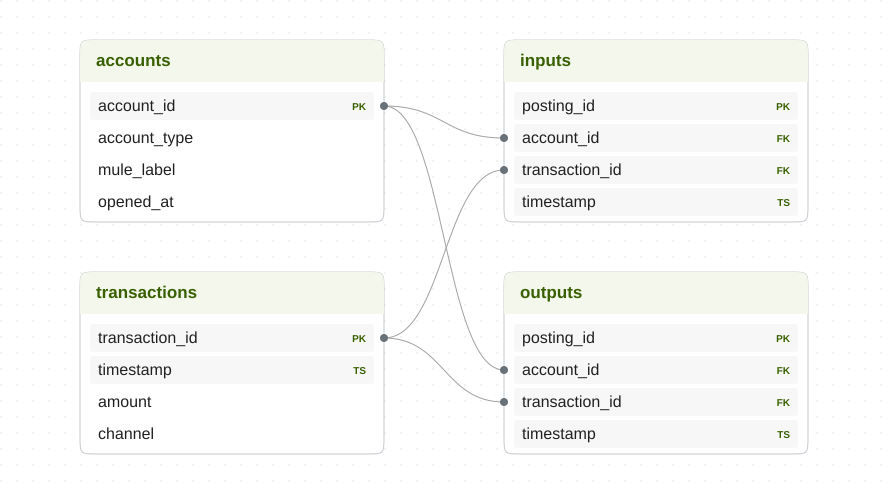

,source,foreign_key,destination
0,inputs,account_id,accounts
1,inputs,transaction_id,transactions
2,outputs,account_id,accounts
3,outputs,transaction_id,transactions


In [6]:
display(graph.visualize(show_cols=True))
display(pd.DataFrame([{"source": edge.src_table, "foreign_key": edge.fkey,
                       "destination": edge.dst_table} for edge in graph.edges]))


Materialize the historical graph. This snapshot stays fixed while fitting and evaluating the model.


In [7]:
snapshot = graph.snapshot()
print("Training snapshot:", snapshot.id)


/tmp/ipykernel_1365695/3370640593.py:1: UserWarning: The kumo.engine scratch directory /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_scratch/synthetic_money_muling-9u3v45ec is on Amazon EBS. Graph sampling and training-table generation read it randomly and run much slower there; local NVMe is recommended.
  snapshot = graph.snapshot()


ingest: table started phase="encode" table=accounts


ingest: table producers complete phase="encode" table=accounts rows=2000 elapsed_ms=23


ingest: Ingestion stage progress phase=Encode table=accounts shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=transactions


ingest: table producers complete phase="encode" table=transactions rows=22921 elapsed_ms=106


... (23 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 4 node tables, 8 edge relations, 70763 nodes, 183368 edges


Training snapshot: 9053ed74e9fac749ec568b04ef4e89a4bd6b94b529ab6908706cf05c626205f8@3aac27d3dfa3cc10


## Define current mule classification

Use a static binary [predictive query](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries) on accounts. The comparison establishes the positive class; supplied training rows below provide the actual outcomes instead of the constant placeholder.
The label represents a simulated intermediary's activity in the observed history. There is no future label window in this example.


In [8]:
QUERY = "PREDICT accounts.mule_label = 1 FOR EACH accounts.account_id"
query = kumo.PredictiveQuery(graph, QUERY)
query.validate()
assert query.get_task_type() == "binary_classification"
print(QUERY)


PREDICT accounts.mule_label = 1 FOR EACH accounts.account_id


## Separate training, validation, and test accounts

Assign whole planted scenarios to approximately 70/15/15 splits, stratifying by whether a scenario contains mules. This keeps each planted network together. Background transfers may cross splits, so this tests classification within one observed network, not generalization to a future period.
Simulation grouping controls the split only; it is never an input feature. Test outcomes are reserved for final assessment.


In [9]:
groups = truth.groupby("network_id", as_index=False).agg(contains_mules=("is_mule", "any"))
train_groups, remaining_groups = train_test_split(
    groups, test_size=0.30, stratify=groups.contains_mules, random_state=SEED
)
validation_groups, test_groups = train_test_split(
    remaining_groups, test_size=0.50, stratify=remaining_groups.contains_mules, random_state=SEED
)
split_by_group = {group: split for split, frame in enumerate((train_groups, validation_groups, test_groups))
                  for group in frame.network_id}
labeled_rows = truth[["account_id", "is_mule"]].rename(columns={"account_id": "ENTITY1", "is_mule": "TARGET1"})
labeled_rows["SPLIT"] = truth.network_id.map(split_by_group).astype("int64")
assert labeled_rows.ENTITY1.is_unique
assert labeled_rows.groupby("SPLIT").TARGET1.nunique().eq(2).all()
assert truth.assign(split=labeled_rows.SPLIT).groupby("network_id").split.nunique().eq(1).all()
labeled_rows.to_parquet(source_dir / "training.parquet", index=False)
test_rows = labeled_rows.loc[labeled_rows.SPLIT == 2].copy()
test_requests = test_rows[["ENTITY1"]].copy()
test_requests.to_parquet(source_dir / "test_requests.parquet", index=False)
display(labeled_rows.groupby("SPLIT").agg(accounts=("ENTITY1", "size"), mule_rate=("TARGET1", "mean")))


,accounts,mule_rate
SPLIT,,
0,1400,0.1
1,300,0.1
2,300,0.1


Create and export the [custom training table](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training-tables#use-custom-training-tables) to verify the rows Engine accepted. `SPLIT` values 0, 1, and 2 mean training, validation, and test. No outcome is copied into a graph table.


In [10]:
training_spec = TrainingTableSpec(split_col="SPLIT")
training_table = kumo.TrainingTable.from_source_table(
    files["training"], training_spec, pq=query, snapshot=snapshot
)
training_table.export(TrainingTableOutputConfig(connector=destination, table_name="training_rows/"))
accepted_rows = pd.read_parquet(output_dir / "training_rows")
pd.testing.assert_frame_equal(
    accepted_rows[["ENTITY1", "TARGET1", "SPLIT"]].sort_values("ENTITY1").reset_index(drop=True),
    labeled_rows.sort_values("ENTITY1").reset_index(drop=True), check_dtype=False,
)
display(accepted_rows.head())


,ENTITY1,TIMESTAMP,TARGET1,SPLIT
0,synthetic-history-account-00000,1970-01-01,False,0
1,synthetic-history-account-00001,1970-01-01,False,0
2,synthetic-history-account-00002,1970-01-01,False,0
3,synthetic-history-account-00003,1970-01-01,False,0
4,synthetic-history-account-00004,1970-01-01,True,0


## Fit a comparison baseline

Fit logistic regression on account age and incoming/outgoing transfer counts, amounts, unique counterparties, and the outgoing-to-incoming amount ratio. Its scaler and estimator see only training accounts. Both models use the same historical data and final test accounts.


In [11]:
accounts = history["accounts"].set_index("account_id")
features = pd.DataFrame({"account_age_days": (CUTOFF - accounts.opened_at).dt.days}, index=accounts.index)
transfers = history["transactions"].merge(
    history["inputs"][["transaction_id", "account_id"]].rename(columns={"account_id": "sender"}),
    on="transaction_id", validate="one_to_one",
).merge(history["outputs"][["transaction_id", "account_id"]].rename(columns={"account_id": "receiver"}),
        on="transaction_id", validate="one_to_one")
for direction, account, counterparty in (("incoming", "receiver", "sender"), ("outgoing", "sender", "receiver")):
    aggregates = transfers.groupby(account).agg(count=("amount", "size"), amount=("amount", "sum"),
                                               counterparties=(counterparty, "nunique"))
    features = features.join(aggregates.add_prefix(f"{direction}_")).fillna(0)
features["outgoing_incoming_ratio"] = features.outgoing_amount / features.incoming_amount.clip(lower=1.0)
assert np.isfinite(features.to_numpy()).all()
train_rows = labeled_rows.loc[labeled_rows.SPLIT == 0]
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
baseline.fit(features.loc[train_rows.ENTITY1], train_rows.TARGET1)
print("Baseline fitted on", len(train_rows), "training accounts.")


Baseline fitted on 1400 training accounts.


## Configure the graph model

Start from the supported [FAST plan](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/model-plan-guide) and select by AUPRC. Four sampling hops can reach a counterparty through `account → posting → transaction → posting → account`; this is not a promise to inspect every transfer chain.
Disable refitting to keep the training population separate from validation and test, and retain training explanations.


In [12]:
plan = query.suggest_model_plan(snapshot, train_table_spec=training_spec, run_mode=RunMode.FAST)
plan.training_job.manual_seed = SEED
plan.training_job.refit_trainval = False
plan.training_job.refit_full = False
plan.training_job.disable_explain = False
plan.training_job.metrics = ["auprc", "auroc"]
plan.training_job.tune_metric = "auprc"
plan.neighbor_sampling.num_neighbors = [[20, 10, 5, 5]]
if SMOKE_MODE:
    plan.training_job.num_experiments = 1
    plan.optimization.max_epochs = 1
    print("Smoke mode: pipeline check only; scores do not measure model quality.")
(output_dir / "model_plan.json").write_text(json.dumps(plan.as_json(), indent=2) + "\n")
print("Tuning metric:", plan.training_job.tune_metric)
print("Neighbor sampling:", plan.neighbor_sampling.num_neighbors)


Tuning metric: auprc
Neighbor sampling: [[20, 10, 5, 5]]


## Train and retain the model

Fit on the supplied rows and historical snapshot, exporting the complete model bundle outside scratch for reuse. Training runs on CPU.


In [13]:
trainer = kumo.Trainer(plan, accelerator="cpu")
fit_result = trainer.fit(
    training_table, snapshot=snapshot,
    export_config=ModelOutputConfig(connector=destination, path="model"),
)
print("Retained model:", output_dir / "model")


GPU Memory: Too Many Hops: 'num_neighbors' exceeds the recommended number of three hops, which can potentially cause a GPU out-of-memory error (got 4 hops).


GPU Memory: Too Many Hops: 'num_neighbors' exceeds the recommended number of three hops, which can potentially cause a GPU out-of-memory error (got 4 hops).


[I 2026-11-09 19:07:40,708] A new study created in memory with name: no-name-24869008-3740-4222-ae0d-0bb40885a452


GPU available: False, used: False


TPU available: False, using: 0 TPU cores



  | Name           | Type                     | Params | Mode  | FLOPs
----------------------------------------------------------------------------
0 | target_encoder | CategoricalTargetEncoder | 0      | train | 0    
1 | metric_store   | MetricStore              | 0      | train | 0    
2 | loss           | BinaryCrossEntropyLoss   | 0      | train | 0    
3 | calibrator     | PlatScaling              | 2      | train | 0    
4 | encoder        | HeteroTensorFrameEncoder | 75.1 K | train | 0    
5 | model          | HeteroGNN                | 2.0 M  | train | 0    
6 | head           | NodePredHead             | 16.9 K | train | 0    
----------------------------------------------------------------------------
2.1 M     Trainable params
0         Non-trainable params
2.1 M     Total params
8.286     Total estimated model params size (MB)
428       Modules in train mode
0         Modules in eval mode
0         Total Flops


... (205 outputs left out)

Testing DataLoader 0: 100%|██████████| 1/1 [00:11<00:00,  0.09it/s]

Testing DataLoader 0: 100%|██████████| 1/1 [00:11<00:00,  0.09it/s]


────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_loss           0.4991932511329651
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


Retained model: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_example_runs/synthetic_money_muling-zkqzt0ut/output/model


## Evaluate on test accounts

Prepare an ID-only [prediction table](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/making-predictions) for the reserved test accounts. Check scores by returned ID rather than assuming response order.


In [14]:
def align_scores(frame, expected_ids):
    expected_ids = list(expected_ids)
    assert len(expected_ids) == len(set(expected_ids))
    assert {"ENTITY", "True_PROB", "False_PROB"} <= set(frame.columns)
    assert frame.ENTITY.is_unique and set(frame.ENTITY) == set(expected_ids)
    aligned = frame.set_index("ENTITY").loc[expected_ids].reset_index()
    probabilities = aligned[["False_PROB", "True_PROB"]].to_numpy()
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-6)
    return aligned

test_population = kumo.PredictionTable.from_source_table(
    files["test_requests"], pq=query, snapshot=snapshot, plan=training_table.generation_plan
)
assert len(pd.read_parquet(test_population.table_path)) == len(test_requests)


Score the test accounts once with the fitted model. The API requires a class threshold; ranking metrics below use probabilities and are unaffected by that threshold.


In [15]:
test_result = trainer.predict(test_population, snapshot=snapshot, binary_classification_threshold=0.5)
test_scores = align_scores(test_result.frame, test_rows.ENTITY1)
baseline_scores = baseline.predict_proba(features.loc[test_rows.ENTITY1])[:, list(baseline.classes_).index(True)]


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


Restoring states from the checkpoint path at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_scratch/synthetic_money_muling-9u3v45ec/trainers/2d5e3d2c52434398b57f70668f1321fc/runs/2d5e3d2c52434398b57f70668f1321fc-predict-dcfd1977f75845d98b6b68b48aa617ca/model_bundle/model/checkpoint/step=0.ckpt


Loaded model weights from the checkpoint at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_scratch/synthetic_money_muling-9u3v45ec/trainers/2d5e3d2c52434398b57f70668f1321fc/runs/2d5e3d2c52434398b57f70668f1321fc-predict-dcfd1977f75845d98b6b68b48aa617ca/model_bundle/model/checkpoint/step=0.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00,  9.26it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00,  8.99it/s]

**Synthetic-data metrics - demonstration only.** Average precision summarizes positive-class retrieval, AUROC measures ranking, and precision/recall at the configured top fraction reflect a fixed review capacity. Compare average precision with the displayed prevalence. Engine need not outperform the baseline on this small simulation.


Synthetic-data metrics — demonstration only
Test accounts: 300; mule prevalence: 10.0%


,average_precision,AUROC,precision_at_budget,recall_at_budget,review_count
Logistic regression,0.506625,0.909383,0.600000,0.300000,15.0
Engine,0.222716,0.734568,0.333333,0.166667,15.0


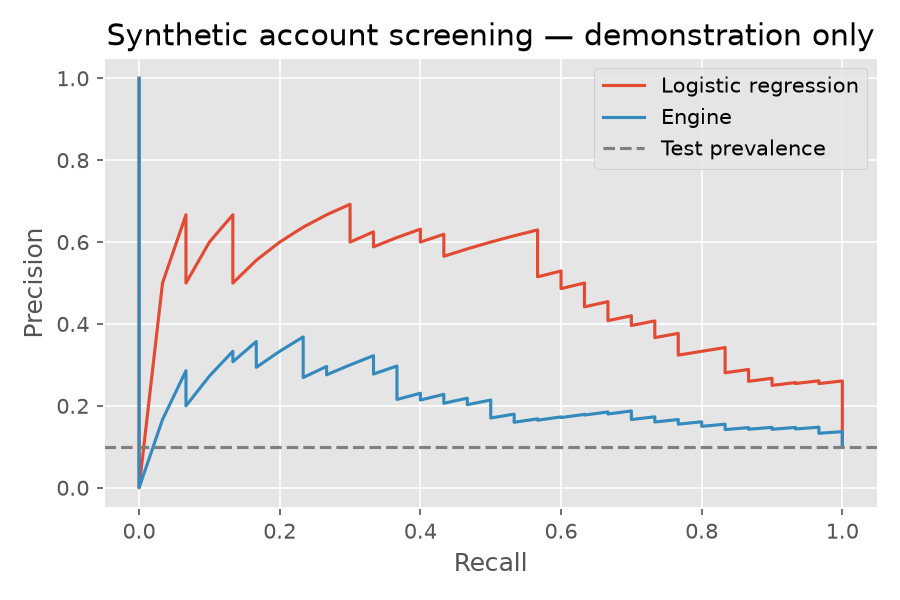

In [16]:
def ranked_accounts(ids, probabilities):
    return pd.DataFrame({"account_id": list(ids), "mule_score": np.asarray(probabilities)}).sort_values(
        ["mule_score", "account_id"], ascending=[False, True], ignore_index=True
    )

def ranking_metrics(ids, actual, probabilities):
    actual = pd.Series(np.asarray(actual, dtype=bool), index=list(ids))
    ranked = ranked_accounts(ids, probabilities)
    review_count = max(1, int(np.ceil(REVIEW_FRACTION * len(ranked))))
    found = int(actual.loc[ranked.account_id.head(review_count)].sum())
    return {"average_precision": average_precision_score(actual, probabilities),
            "AUROC": roc_auc_score(actual, probabilities),
            "precision_at_budget": found / review_count,
            "recall_at_budget": found / int(actual.sum()), "review_count": review_count}

probability_sets = {"Logistic regression": baseline_scores, "Engine": test_scores.True_PROB.to_numpy()}
metrics = pd.DataFrame({name: ranking_metrics(test_rows.ENTITY1, test_rows.TARGET1, probability)
                        for name, probability in probability_sets.items()}).T
print("Synthetic-data metrics — demonstration only" + ("; smoke mode" if SMOKE_MODE else ""))
print(f"Test accounts: {len(test_rows)}; mule prevalence: {test_rows.TARGET1.mean():.1%}")
display(metrics)
metrics.to_csv(output_dir / "test_metrics.csv", index_label="model")

fig, ax = plt.subplots(figsize=(6, 4))
for name, probability in probability_sets.items():
    precision, recall, _ = precision_recall_curve(test_rows.TARGET1, probability)
    ax.plot(recall, precision, label=name)
ax.axhline(test_rows.TARGET1.mean(), color="gray", linestyle="--", label="Test prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Synthetic account screening — demonstration only")
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "precision_recall.png", dpi=150)
plt.close(fig)
display(Image(filename=str(output_dir / "precision_recall.png")))


## Batch predictions

Append the reserved accounts and their transfers/postings to the original graph sources. They are newly ingested records with history before the same cutoff, rather than a later-time forecast. Their true outcomes stay in the simulation variables and are never passed to prediction.
New Parquet parts make the source change explicit while preserving the historical training snapshot.


In [17]:
check_network(new_frames)
for name, frame in new_frames.items():
    key = {"accounts": "account_id", "transactions": "transaction_id",
           "inputs": "posting_id", "outputs": "posting_id"}[name]
    assert set(frame[key]).isdisjoint(history[name][key])
    assert frame.dtypes.equals(history[name].dtypes)
    frame.to_parquet(source_dir / name / "new.parquet", index=False)
scoring_requests = new_frames["accounts"][["account_id"]].rename(columns={"account_id": "ENTITY1"})
assert set(scoring_requests.columns) == {"ENTITY1"}
assert set(scoring_requests.ENTITY1).isdisjoint(labeled_rows.ENTITY1)
scoring_requests.to_parquet(source_dir / "scoring_requests.parquet", index=False)
scoring_snapshot = graph.snapshot()
assert scoring_snapshot.id != snapshot.id
print("New accounts to score:", len(scoring_requests))


ingest: table started phase="encode" table=accounts


ingest: table producers complete phase="encode" table=accounts rows=2100 elapsed_ms=28


ingest: Ingestion stage progress phase=Encode table=accounts shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=transactions


ingest: table producers complete phase="encode" table=transactions rows=24067 elapsed_ms=101


ingest: Ingestion stage progress phase=Encode table=transactions shard=None progress_pct=100 current=1 total=1


... (22 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 4 node tables, 8 edge relations, 74301 nodes, 192536 edges


New accounts to score: 100


Materialize the new account IDs against the refreshed snapshot and verify the exact accepted scoring population.


In [18]:
prediction_table = kumo.PredictionTable.from_source_table(
    files["scoring_requests"], pq=query, snapshot=scoring_snapshot, plan=training_table.generation_plan
)
accepted_population = pd.read_parquet(prediction_table.table_path)
assert accepted_population.ENTITY1.is_unique
assert set(accepted_population.ENTITY1) == set(scoring_requests.ENTITY1)
assert not any(column.startswith("TARGET") for column in accepted_population)
display(accepted_population.head())


,ENTITY1,TIMESTAMP
0,synthetic-new-account-00000,1970-01-01
1,synthetic-new-account-00001,1970-01-01
2,synthetic-new-account-00002,1970-01-01
3,synthetic-new-account-00003,1970-01-01
4,synthetic-new-account-00004,1970-01-01


Score all new accounts with the trained model in one batch. Review selection below uses the configured ranking budget, not the API’s 0.5 class threshold.


In [19]:
prediction_result = trainer.predict(
    prediction_table, snapshot=scoring_snapshot, binary_classification_threshold=0.5
)
batch_scores = align_scores(prediction_result.frame, scoring_requests.ENTITY1)


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


Restoring states from the checkpoint path at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_scratch/synthetic_money_muling-9u3v45ec/trainers/2d5e3d2c52434398b57f70668f1321fc/runs/2d5e3d2c52434398b57f70668f1321fc-predict-b0d9553dd40742ce897fb5c45b2ec6af/model_bundle/model/checkpoint/step=0.ckpt


Loaded model weights from the checkpoint at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_scratch/synthetic_money_muling-9u3v45ec/trainers/2d5e3d2c52434398b57f70668f1321fc/runs/2d5e3d2c52434398b57f70668f1321fc-predict-b0d9553dd40742ce897fb5c45b2ec6af/model_bundle/model/checkpoint/step=0.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 14.76it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 14.07it/s]

### Inspect and save the review queue

Expect one row per requested account. `mule_score` is the positive-class probability for the simulated task; `review_rank` orders it descending, breaking ties by account ID. `review_flag` selects the configured top fraction for illustration, and `as_of` records the feature cutoff. Save and reload the full queue as Parquet.


In [20]:
predictions = ranked_accounts(batch_scores.ENTITY, batch_scores.True_PROB)
predictions.insert(1, "as_of", pd.Series(CUTOFF, index=predictions.index, dtype="datetime64[ns]"))
predictions["review_rank"] = np.arange(1, len(predictions) + 1)
review_count = max(1, int(np.ceil(REVIEW_FRACTION * len(predictions))))
predictions["review_flag"] = predictions.review_rank.le(review_count)
assert len(predictions) == N_NEW_ACCOUNTS and predictions.review_flag.sum() == review_count
prediction_path = output_dir / "money_mule_scores.parquet"
predictions.to_parquet(prediction_path, index=False)
pd.testing.assert_frame_equal(predictions, pd.read_parquet(prediction_path))
display(predictions.head(10))
print("Saved:", prediction_path)


,account_id,as_of,mule_score,review_rank,review_flag
0,synthetic-new-account-00014,2026-10-01,0.600413,1,True
1,synthetic-new-account-00085,2026-10-01,0.538028,2,True
2,synthetic-new-account-00090,2026-10-01,0.418411,3,True
3,synthetic-new-account-00035,2026-10-01,0.384530,4,True
4,synthetic-new-account-00028,2026-10-01,0.341497,5,True
5,synthetic-new-account-00055,2026-10-01,0.302437,6,False
6,synthetic-new-account-00075,2026-10-01,0.301088,7,False
7,synthetic-new-account-00001,2026-10-01,0.297196,8,False
8,synthetic-new-account-00040,2026-10-01,0.267798,9,False
9,synthetic-new-account-00030,2026-10-01,0.253984,10,False


Saved: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_example_runs/synthetic_money_muling-zkqzt0ut/output/money_mule_scores.parquet


## Retain and reuse

The retained model bundle contains the fitted model; keep compatible source tables and the query alongside it. Rebuild the graph, reload without fitting, and verify the same account scores. In a fresh process, configure scratch first and reconstruct the saved query and ID-only population.
See [publish and retrieve models](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/publish-and-retrieve-models) and [schedule prediction jobs](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/deploy-a-model/schedule-prediction-jobs) for reuse beyond this run.


In [21]:
(output_dir / "query.txt").write_text(QUERY + "\n")
(output_dir / "scoring_context.json").write_text(json.dumps({
    "cutoff": CUTOFF.isoformat(), "review_fraction": REVIEW_FRACTION, "seed": SEED,
    "history_days": HISTORY_DAYS, "smoke_mode": SMOKE_MODE,
}, indent=2) + "\n")
reloaded_files, reloaded_graph = build_graph(source_dir)
reloaded_snapshot = reloaded_graph.snapshot()
reloaded_query = kumo.PredictiveQuery(reloaded_graph, QUERY)
reloaded_query.validate()
reloaded_trainer = kumo.Trainer.load(output_dir / "model", accelerator="cpu")
reloaded_population = kumo.PredictionTable.from_source_table(
    reloaded_files["scoring_requests"], pq=reloaded_query, snapshot=reloaded_snapshot,
    plan=reloaded_trainer.training_table_generation_plan,
)
reloaded_result = reloaded_trainer.predict(
    reloaded_population, snapshot=reloaded_snapshot, binary_classification_threshold=0.5
)
reloaded_scores = align_scores(reloaded_result.frame, scoring_requests.ENTITY1)
np.testing.assert_allclose(reloaded_scores.True_PROB, batch_scores.True_PROB, rtol=1e-5, atol=1e-6)
print("Reloaded model reproduced all", len(reloaded_scores), "account scores.")


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


Restoring states from the checkpoint path at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_scratch/synthetic_money_muling-9u3v45ec/trainers/efdc07bf03524830b7452bb69217c69a/runs/efdc07bf03524830b7452bb69217c69a-predict-c4efc516daa84ff6955d5008f704d8f8/model_bundle/model/checkpoint/step=0.ckpt


Loaded model weights from the checkpoint at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_scratch/synthetic_money_muling-9u3v45ec/trainers/efdc07bf03524830b7452bb69217c69a/runs/efdc07bf03524830b7452bb69217c69a-predict-c4efc516daa84ff6955d5008f704d8f8/model_bundle/model/checkpoint/step=0.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 17.33it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 16.36it/s]

Reloaded model reproduced all 100 account scores.


## Inspect training explanations

[Training explanations](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/model-explainability) describe selected test examples, not the new scoring batch. Inspect column sensitivity for the selected experiment and preserve it outside scratch. Sensitivity is not a causal effect; missing artifacts require checking the fit logs.


In [22]:
selection_paths = list(Path(fit_result.bundle_dir).parent.rglob("best_trainer.json"))
if len(selection_paths) != 1:
    print("No unambiguous selected experiment found; inspect training logs for explanation status.")
else:
    selection_path = selection_paths[0]
    selection = json.loads(selection_path.read_text())
    selected_experiment = selection_path.parent / Path(selection["best_trainer"]).name
    gradient_path = selected_experiment / "explain_test" / "scores.csv"
    if gradient_path.is_file():
        sensitivity = pd.read_csv(gradient_path)
        assert np.isfinite(sensitivity.score).all()
        display(sensitivity[["table", "column", "score"]].sort_values("score", ascending=False).head(10))
        sensitivity.to_csv(output_dir / "training_column_sensitivity.csv", index=False)
    else:
        print("Column sensitivity was not generated; inspect the explanation step in the fit logs.")


,table,column,score
0,accounts,opened_at,0.606126
1,outputs,timestamp,0.162248
2,inputs,timestamp,0.128402
3,transactions,timestamp,0.039717
4,accounts,account_type,0.028954
5,transactions,amount,0.024397
6,transactions,channel,0.010158


## Cleanup

Keep the source data, model, scores, plot, and any explanation export under the printed retained run directory. Enable `REMOVE_RUN_SCRATCH` in the parameters cell to remove only this run's scratch after the reload check; subsequent scoring must rebuild snapshots. Copy retained files to durable storage if the local machine is temporary.


In [23]:
if REMOVE_RUN_SCRATCH:
    shutil.rmtree(scratch_dir)
    print("Removed this run's scratch:", scratch_dir)
print("Retained run:", run_dir)


Retained run: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_money_muling_detection/20261109T190733Z/kumo_example_runs/synthetic_money_muling-zkqzt0ut
